# Introduction
This Jupyter notebook is intended to be a reformatted version of code originally written by Dr. Leia Price.

### Required Packages

Matplotlib, NumPy, Pandas, and SciPy

### Purpose
This notebook builds upon `floquet_analysis.ipynb` and interprets the arrays of floquet exponents calculated from it, analyzing the field spectra and mass profiles for each array of $q,\kappa^2$ and $c_k$ found in `floquet_analysis.ipynb`.

### Background
As a review, the Floquet exponents, $\gamma_k$, were found by solving a particular class of the Hill's equation known as Lamé's equation. Note that we are working with $c_k \equiv \gamma_k \cdot Y$ where $Y$ is the period of the elliptic cosine with modulus amplitude of $1/2$:
$$
\ddot{X}+\left[A+2qP_{\mathrm{T}(t)} \right]X = 0
$$
This is the form of Hill's equation, where $A$ and $q$ are free parameters and $P_\mathrm{T}(t)$ is some periodic function with period of $T$.

In this case, our periodic function is an elliptic function, specifically the elliptic cosine.
$$
X_k''+ \left[\frac{k^2}{\lambda\Phi^2}+\frac{g^2}{\lambda}\mathrm{cn}^2\left(\sqrt{\lambda}\Phi\eta,\frac{1}{2}\right)\right]X_k=0
$$
This differential equation can be found by solving for the equations of motions given the following potential:
$$
V(\phi,\chi)=\frac{\lambda}{4}\phi^4+\frac{1}{2}g^2\phi^2\chi^2
$$

We defined $\kappa^2\equiv\frac{k^2}{\lambda\Phi^2}$ and $q\equiv\frac{g^2}{\lambda}$,and $y=\sqrt{\lambda}\Phi\eta$, and our differential equation fits the Hill's equation form more nicely:

$$
X_k''+ \left[\kappa^2+q\cdot\mathrm{cn}^2\left(y,\frac{1}{2}\right)\right]X_k=0
$$

$X_k$ will have solutions proportional to 

## Imports

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.integrate import solve_ivp
from scipy import fft
from scipy.integrate import simpson
from scipy.integrate import cumulative_trapezoid
import natural_units as nu
from scipy.special import ellipj
from scipy.special import ellipk
from scipy.special import ellipe
from scipy.special import spherical_jn # in integration
import os

In [3]:
plt.rcParams["font.family"] = "serif"
plt.rcParams["mathtext.fontset"] = "dejavuserif"
plt.rcParams['font.size'] = 27
plt.rcParams['lines.linewidth'] = 1.7
plt.rc('legend',fontsize=12, title_fontsize=14)
plt.rcParams['figure.figsize'] = (10, 7)  # default is (6.4, 4.8)

## Hellper Functions


Defining the Inflaton field's potential:

In [4]:
def V(phi,lam=1e-13):
    return lam / 4 * phi**4

Defining effective mass:
Generally, to find the effective mass of some field $\varphi$
$$
m_{\mathrm{eff},\varphi}^2 = \frac{\mathrm{d}^2V(\varphi)}{\mathrm{d}\varphi^2}
$$
Our expressions for the effective masses of $\phi$ and $\chi$ are:
$$
m_{\mathrm{eff},\phi} = \frac{\mathrm{d}^2V(\phi,\chi)}{\mathrm{d}\phi^2}=3\lambda\phi^2
$$
$$
m_{\mathrm{eff},\chi}^2 = \frac{\mathrm{d}^2V(\phi,\chi)}{\mathrm{d}\chi^2}=g^2\phi^2
$$

Notice, that we defined $q \equiv \frac{g^2}{\lambda}$ and analytically $\phi \propto \mathrm{cn^2(...,\frac{1}{2})}$, so $\frac{m_{\mathrm{eff},\chi}^2}{\lambda}=q\cdot\overline{\mathrm{cn}^2}$.

The following function accounts for dividing the effective mass squared by $\lambda$.

In [5]:
cn_squared_avg = ((-0.5)*(ellipk(0.5))+ellipe(0.5))/(0.5*ellipk(0.5)) # time averaged period of the elliptic cosine function w./ modulus amplitude of 1/2
def meff_squared(q):
    """ 
    calculates the effective mass of a given field in terms of our dimensionless quantities.
    Args:
        q (float): g^2/\lambda
    """
    return q * cn_squared_avg # returns m_eff_phi if q = 3.
# m_eff_phi = np.sqrt(meff(3)) 
# m_eff_chi = np.sqrt(meff(q)) 
print(cn_squared_avg)

0.4569465810444637


<>:3: SyntaxWarning: invalid escape sequence '\l'
<>:3: SyntaxWarning: invalid escape sequence '\l'
/var/folders/0t/tkrfdh952yq9xynmvfgqpwwc0000gn/T/ipykernel_74671/824074819.py:3: SyntaxWarning: invalid escape sequence '\l'
  """


The following function does a lot of things under the hood.
namely, defining these values:
 ## to do, write 

**energy per particle $\kappa$**
$$
\omega_\kappa = \sqrt{m_\mathrm{eff}^2+\kappa^2}
$$

**mode function $v_\kappa$**
$$
v_\kappa = \frac{e^{\gamma_\kappa \eta}}{\sqrt{2 \omega_\kappa}}
$$

In [6]:
# def field(gk, k, r, T):  # most important function, IFTing resonance bands ***NEW VERSION***
#     ok = np.sqrt(meff_squared(q) + k**2)  # mode frequency omega_k
#     vk = np.exp(gk * T) / np.sqrt(ok) / np.sqrt(2)  # mode function v_k

#     nk = ok * vk**2 - 0.5  # -1/2 to regularize
#     rhok = ok * nk
#     r_j0 = simpson(spherical_jn(0, np.outer(k, r)) * k**2 * rhok * np.sqrt(2/np.pi) * k, np.log(k))

#     return r_j0

def field(q, k, ck, r, N):  # most important function, IFTing resonance bands
    ok = np.sqrt(meff_squared(q) + k**2)  # mode frequency omega_k #TODO: examine why q is global.
    vk = np.exp(ck * N) / np.sqrt(ok) / np.sqrt(2)  # mode function v_k
    fk = (vk - 1 / np.sqrt(ok) / np.sqrt(2))* k**1.5

    f_j0 = simpson(spherical_jn(0, np.outer(k, r)) * k**2 * fk * np.sqrt(2/np.pi) * k, np.log(k))

    nk = ok * vk**2 - 0.5  # -1/2 to regularize
    rhok = ok * nk
    r_j0 = simpson(spherical_jn(0, np.outer(k, r)) * k**2 * rhok * np.sqrt(2/np.pi) * k, np.log(k))

    # plotting Fourier-space spectra of field number and energy densities
    plt.clf()
    plt.loglog(k, nk, 'r')
    plt.ylabel(r'$n_k$')
    plt.xlabel(r'$k/\sqrt{\lambda}\Phi$')
    plt.tight_layout() 
    plt.savefig(dirname+'nk.png')

    plt.clf()
    plt.loglog(k, rhok, 'r')
    plt.ylabel(r'$\rho_{\chi k}/\sqrt{\lambda}\Phi$')
    plt.xlabel(r'$k/\sqrt{\lambda}\Phi$')
    plt.tight_layout() 
    plt.savefig(dirname+'rhok.png')

    return r_j0, f_j0

In [13]:
# def fvar(gk, k, T):
#     omega_k = np.sqrt(meff_squared(q) + k**2)  # mode frequency omega_k
#     vk = np.exp(gk * T) / np.sqrt(omega_k) / np.sqrt(2)  # mode function v_k
#     vkr = vk - 1 / (np.sqrt(omega_k) * np.sqrt(2))
#     return simpson(np.sqrt(2/np.pi) * k**2 * vkr**2, k)
def fvar(q, k, ck, N):
    ok = np.sqrt(meff_squared(q) + k**2)  # mode frequency omega_k
    vk = np.exp(ck * N) / np.sqrt(ok) / np.sqrt(2)  # mode function v_k
    vkr = vk - 1 / (np.sqrt(ok) * np.sqrt(2))  # regularized so that vacuum gives zero
    return simpson(4*np.pi * k**2 * vkr**2, k) / (2*np.pi)**3

In [14]:
# xlsx = 'test_single_band_jupyter'
dirname = 'qsheets/'
filename = dirname + 'qe7_LSODA_high_tolerances'

In [15]:
def Wg(y, R):  # Gaussian window function
    return np.exp(-y**2 / R**2)

def Mg(dr, r):  # deltaM with Gaussian window
    return np.array([0]+[simpson(4*np.pi*r[:i+1]**2 * dr[:i+1] * Wg(r[:i+1], r[i+1]), r[:i+1]) for i in range(len(r)-1)])

def Mt(dr, r):  # deltaM with tophat window window
    return cumulative_trapezoid(4*np.pi*r**2 * dr, r, initial=0)


## Plotting Mass Enclosed

In [16]:
def load_qsheet(filename):
    
    sheet_name = filename+ '.xlsx'
    q = np.squeeze(pd.read_excel(sheet_name, sheet_name='qs').values)
    # power = int(np.log10(q))

    # kappas = np.squeeze(pd.read_excel(sheet_name, sheet_name=f'ks_{power}').values) 
    kappas = np.squeeze(pd.read_excel(sheet_name, sheet_name=f'k_squared_7').values) 
    ck = np.squeeze(pd.read_excel(sheet_name, sheet_name=f'gs_7').values)
    # gamma_k = np.squeeze(pd.read_excel(sheet_name, sheet_name=f'gs_{power}').values)
    return q, kappas, ck

q, kappas, ck = load_qsheet(filename)
# log10g2 = np.log10(q) - 14 # 14 is log_10(\lambda)

# parameters
lam = 1e-14
# g2 = q * lam # for q = 1e7, lam = 1e-14, g2 = 1e-7
g2 = q * lam
print(g2)
varc = 0
N = 0
while varc < cn_squared_avg / g2:
    N += 1  # step BEFORE recalculating varchi
    varc = fvar(q, kappas, ck, N)
N -= 1  # undo overshoot from last recalculation
print('N =', N) 
# Y = 4*ellipk(0.5) # period of elliptic cosine

# Phi_list = [1,2,3,4] #in units of reduced Planck Mass!
# def plot_mass_enc(q, kappas, ck, Phis,gauss=False):
#     """
#     Plots the mass enclosed for a given q as a function of r. Includes Hubble Radius & related black hole enclosed mass.
#     Args:
#         q (_type_): _description_
#         kappas (_type_): _description_
#         ck (_type_): _description_
#         Phis (_type_): _description_
#         gauss (bool, optional): _description_. Defaults to False.
#     """
#     r = 1 / kappas[::-1]
#     rp = r.copy()
#     # r_vac = field(0, kappas, r, T)
#     r_res, f_res = field(ck, kappas, r, N)
#     massmult = 1
#     plt.clf()
    
# # plot black hole mass vs radius to compare to phi mass
    
#     for Phi in Phis:
#         plt.clf()
#         rp = r.copy()
        
#         # parameters
#         H = Phi/np.sqrt(12)
#         lMpl = -np.log10(Phi) + 7  # assuming lambda=10^-14
#         rH = 1/H
#         massmult = 1
#         cm = True
#         gram = True
#         if cm:
#             rp *= 10**lMpl / nu.Mpl / nu.m * 100
#         if gram:
#             massmult = 10**(-lMpl) * nu.Mpl / nu.g
#         if lMpl==0:
#             string = r'$\sqrt{\lambda}\Phi/M_\mathrm{{pl}}=1$'
#         else:
#             string = r'$\sqrt{{\lambda}}\Phi/M_\mathrm{{pl}}=10^{{{}}}$'.format(round(-lMpl, 2))
#         if gauss:
#             plt.plot(rp, Mg(r_res, r) * massmult, '--r', alpha=0.7)
#         plt.loglog(rp, Mt(r_res, r) * massmult, 'r', label=r'$M_\mathrm{encl}$')
#         # Plotting the Hubble Radius
#         if cm:
#             plt.axvline(10**lMpl / nu.Mpl / nu.m * 100 / H, color='k',
#                 label=r'Hubble radius with $\Phi/M_\mathrm{{pl}}={}$'.format(round(Phi, 2)))
#         else:
#             # plt.plot([1/H, 1/H], plt.ylim(), 'k', label=r'Hubble radius with $\Phi/M_\mathrm{{pl}}={}$'.format({Phi}))
#             # plt.axvline(rH, ls='--', lw=1.2, alpha=0.8,label=r'Hubble radius with $\Phi/M_\mathrm{{pl}}={}$'.format({Phi}))
#             plt.axvline(rH, color='k', label=r'$R_H$')
#             if Phi==1:
#                 # plt.plot([1/H, 1/H], plt.ylim(), 'k', label=r'$R_H$')
#                 plt.axvline(rH, ls='--', lw=1.2, alpha=0.8)
#                 # plt.loglog(rp, 10**(2*lMpl) * r/2 * massmult, ':b', label=r'$M_\mathrm{BH}$')
#             else:
#                 # plt.plot([1/H, 1/H], plt.ylim(), 'k')
#                 plt.axvline(rH, ls='--', lw=1.2, alpha=0.8)
#                 # plt.loglog(rp, 10**(2*lMpl) * r/2 * massmult, ':b')
#         plt.loglog(rp, 10**(2*lMpl) * r/2 * massmult, ':b', label=r'$M_\mathrm{BH}$ with '+string)
#         if gram:
#             plt.ylabel(r'mass [g] with '+string)
#         else:
#             plt.ylabel(r'$M/\sqrt{\lambda}\Phi$')
#         if cm:
#             plt.xlabel(r'radius [cm] with '+string)
#         else:
#             plt.xlabel(r'$\sqrt{\lambda}\Phi r$')
#         plt.legend()
#         plt.tight_layout()
#         file_path = f"plots/q_6.1_g2_-7.9_Phi/Mpl_{Phi}.png"
#         output_dir = os.path.dirname(file_path)
#         if output_dir:
#             os.makedirs(output_dir, exist_ok=True)
#         plt.savefig(file_path)
#         plt.show()
# plot_mass_enc(q, kappas, ck, Phi_list)

1e-07
N = 4


/var/folders/0t/tkrfdh952yq9xynmvfgqpwwc0000gn/T/ipykernel_74671/55885438.py:10: DeprecationWarning: You are passing x=[1.00000000e-03 1.13531953e-03 1.28895044e-03 1.46337062e-03
 1.66139325e-03 1.88621221e-03 2.14145356e-03 2.43123406e-03
 2.76022752e-03 3.13374022e-03 3.55779649e-03 4.03923585e-03
 4.58582337e-03 5.20637485e-03 5.91089906e-03 6.71075917e-03
 7.61885597e-03 8.64983601e-03 9.82032779e-03 1.11492100e-02
 1.26579159e-02 1.43707791e-02 1.63154263e-02 1.85232222e-02
 2.10297759e-02 2.38755154e-02 2.71063390e-02 3.07743562e-02
 3.49387277e-02 3.96666201e-02 4.50342886e-02 5.11283076e-02
 5.80469663e-02 6.59018548e-02 7.48196631e-02 8.49442250e-02
 9.64388379e-02 1.09488897e-01 1.24304883e-01 1.41125762e-01
 1.60222834e-01 1.81904113e-01 2.06519293e-01 2.34465388e-01
 2.66193135e-01 3.02214266e-01 3.43109759e-01 3.89539212e-01
 4.42251476e-01 5.02096740e-01 5.70040237e-01 6.47177816e-01
 7.34753616e-01 8.34180133e-01 9.47061000e-01 1.07521685e+00
 1.22071470e+00 1.38590124e

4


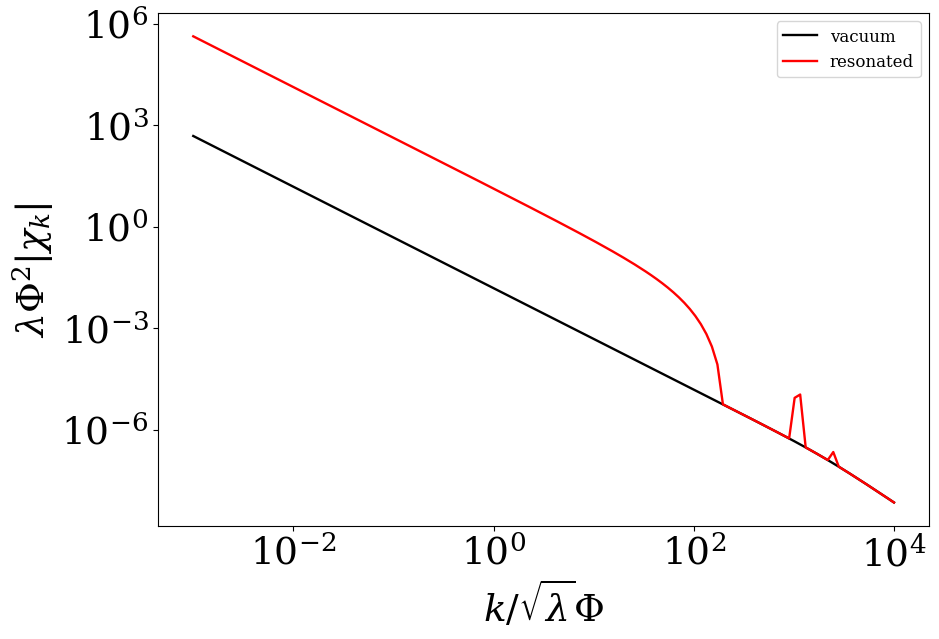

In [17]:
# set up field spectra
fk_vac = (meff_squared(q) + kappas**2)**-0.25 / kappas**1.5 / np.sqrt(2)  # field modes for vacuum
fk_res = fk_vac.copy()
fk_res = fk_res * np.exp(ck * N)  # field modes that have been resonantly amplified after one period
print(N)
# plot the field spectra fk
plt.clf()
plt.loglog(kappas, fk_vac, 'k', label='vacuum')
plt.loglog(kappas, fk_res, 'r', label='resonated')
plt.legend()
plt.ylabel(r'$\lambda\Phi^2|\chi_k|$')
plt.xlabel(r'$k/\sqrt{\lambda}\Phi$')
plt.tight_layout() 
plt.savefig(f'{filename}_spectra_andrew.png')
# plt.show()